In [1]:
from dynamic_catalysis_model import cycle_flux_fn, map_graph_weights_ten_states
import networkx as nx
import numpy as np
oscMidpoint = 0
k_bT = 1
dG_1 = 2
dG_2 = 2

dG_1_w = 1
dG_2_w = 3
epsilon = 0

alpha_21 = 1
alpha_32 = 1

alpha_54 = 1 
alpha_65 = 1 
gamma = 20000
N = 10
G = nx.Graph()
G.add_nodes_from([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
G.add_edges_from([(0, 1), (1, 2), (0,2), (2, 3), (3, 4), (4,2), (5, 6), (6, 7), (5, 7), (7, 8), (8, 9), (9, 7), (0, 5), (1, 6), (2, 7), (3, 8), (4, 9)])
node_indices = list(range(N))
spanTreesGraph = [i for i in nx.SpanningTreeIterator(G)]
epsilon_list = np.linspace(-10,10,100)
J_tot_list_cycle_r = []
J_tot_list_cycle_w = []

def max_rate_dummy(**params):
    return 1

for epsilon in epsilon_list:
    epsilon_1 = epsilon
    epsilon_2 = epsilon
    alpha_14 = 1e-11
    alpha_41 = 1e-11
    right_cycles = [[2,3,4], [7,8,9], [2, 7, 8, 9, 4], [7, 2, 3, 4, 9], [7,2,3,8,9], [2,7,8,3,4], [2,3,8,9,7], [7,8,3,4,9]]
    wrong_cycles = [[2,1,0], [7,6,5], [2, 7, 6, 5, 0], [7, 2, 1, 0, 5], [7,2,1,6,5], [2,7,6,1,0], [2,1,6,5,7], [7,6,1,0,5]]
    J_tot_r, J_tot_w = cycle_flux_fn(right_cycles, wrong_cycles, G, [(0,2), (5,7), (4,2), (9,7)], max_ss_rate_fn=max_rate_dummy, weight_mapping_fn=map_graph_weights_ten_states, alpha_32=alpha_32, \
                                              alpha_21=alpha_21, alpha_54=alpha_54, alpha_65=alpha_65,\
                                              alpha_21_w=alpha_21, alpha_32_w=alpha_32, alpha_54_w=alpha_54, alpha_65_w=alpha_65, dG_1=dG_1, dG_2=dG_2, dG_1_w = dG_1_w, dG_2_w = dG_2_w, \
                                              gamma=gamma, epsilon_1=epsilon_1, epsilon_2=epsilon_2, k_bT=k_bT, alpha_14=alpha_14, alpha_41=alpha_41)
    J_tot_list_cycle_r.append(J_tot_r * max_rate_dummy())
    J_tot_list_cycle_w.append(J_tot_w * max_rate_dummy())



<>:12: SyntaxWarning: invalid escape sequence '\e'
<>:13: SyntaxWarning: invalid escape sequence '\ '
<>:12: SyntaxWarning: invalid escape sequence '\e'
<>:13: SyntaxWarning: invalid escape sequence '\ '
/var/folders/98/m6nhh0gx4nsgd2v7r1tl07cc0000gn/T/ipykernel_68097/3756623174.py:12: SyntaxWarning: invalid escape sequence '\e'
  plt.xlabel('$\epsilon \ [k_B T]$', fontsize=9, fontdict={'family': 'sans-serif'})
/var/folders/98/m6nhh0gx4nsgd2v7r1tl07cc0000gn/T/ipykernel_68097/3756623174.py:13: SyntaxWarning: invalid escape sequence '\ '
  plt.ylabel('$J_{tot} \ [s^{-1}]$', fontsize=9, fontdict={'family': 'sans-serif'})
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Generic family 'sans-serif' not found because none of the following families were 

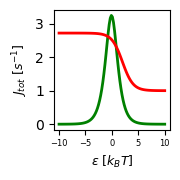

In [2]:
import matplotlib.pyplot as plt
plt.figure(figsize=(1.9,1.9))

# s3 = figure(title="Flux", x_range=(-10, 10), y_range=(0,5), tools="", toolbar_location=None, width=170, height=170)
plt.rcParams['font.sans-serif'] = ['Lucida Sans']
# plt.xlim(-10, 10)
# plt.ylim(0, 5)
plt.plot(epsilon_list, J_tot_list_cycle_r, color='green', label='Total Flux', linewidth=2,)
plt.plot(epsilon_list, [J_tot_list_cycle_w[i] for i in range(len(epsilon_list))], color='red', label='Total Flux', linewidth=2, )
# plt.plot(epsilon_list, J_limit_1_list, color='#92278f', linestyle='dashdot', label='Limit 1', linewidth=2)
# plt.plot(epsilon_list, J_limit_2_list, color='#f7941d', linestyle='dashdot', label='Limit 2', linewidth=2)
plt.xlabel('$\epsilon \ [k_B T]$', fontsize=9, fontdict={'family': 'sans-serif'})
plt.ylabel('$J_{tot} \ [s^{-1}]$', fontsize=9, fontdict={'family': 'sans-serif'})
plt.xticks([-10, -5, 0, 5, 10], fontsize=6)
# plt.yticks([i for i in range(0, 6)], fontsize=6)
ax = plt.gca()
for tick in ax.get_xticklabels():
    tick.set_fontname("Lucida Sans")
for tick in ax.get_yticklabels():
    tick.set_fontname("Lucida Sans")
# idx = np.argmin(np.abs(epsilon_list - epsilon_list[np.where(np.array(J_tot_list) == np.max(J_tot_list))[0][0]]))
# plt.scatter(epsilon_list[idx], J_tot_list[idx], color='red', s=50, label='Current Point')
# plt.legend()
plt.tight_layout()

<>:12: SyntaxWarning: invalid escape sequence '\e'
<>:13: SyntaxWarning: invalid escape sequence '\ '
<>:12: SyntaxWarning: invalid escape sequence '\e'
<>:13: SyntaxWarning: invalid escape sequence '\ '
/var/folders/98/m6nhh0gx4nsgd2v7r1tl07cc0000gn/T/ipykernel_68097/802484179.py:12: SyntaxWarning: invalid escape sequence '\e'
  plt.xlabel('$\epsilon \ [k_B T]$', fontsize=9, fontdict={'family': 'sans-serif'})
/var/folders/98/m6nhh0gx4nsgd2v7r1tl07cc0000gn/T/ipykernel_68097/802484179.py:13: SyntaxWarning: invalid escape sequence '\ '
  plt.ylabel('$J_{tot} \ [s^{-1}]$', fontsize=9, fontdict={'family': 'sans-serif'})
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Generic family 'sans-serif' not found because none of the following families were fo

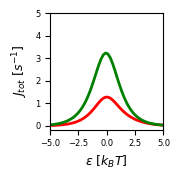

In [3]:
plt.figure(figsize=(1.9,1.9))

plt.plot(epsilon_list, [J_tot_list_cycle_r[i]/J_tot_list_cycle_w[i] for i in range(len(epsilon_list))], color='red', label='Selectivity', linewidth=2,)
plt.plot(epsilon_list, J_tot_list_cycle_r, color='green', label='Total Flux', linewidth=2,)

# plt.plot(epsilon_list, J_limit_1_list, color='#92278f', linestyle='dashdot', label='Limit 1', linewidth=2)
# plt.plot(epsilon_list, J_limit_2_list, color='#f7941d', linestyle='dashdot', label='Limit 2', linewidth=2)
# s3 = figure(title="Flux", x_range=(-5, 5), y_range=(0,5), tools="", toolbar_location=None, width=170, height=170)
plt.rcParams['font.sans-serif'] = ['Lucida Sans']
plt.xlim(-5, 5)
# plt.ylim(0, 5)
plt.xlabel('$\epsilon \ [k_B T]$', fontsize=9, fontdict={'family': 'sans-serif'})
plt.ylabel('$J_{tot} \ [s^{-1}]$', fontsize=9, fontdict={'family': 'sans-serif'})
plt.xticks([-5, -2.5, 0, 2.5, 5], fontsize=6)
plt.yticks([i for i in range(0, 6)], fontsize=6)
ax = plt.gca()
for tick in ax.get_xticklabels():
    tick.set_fontname("Lucida Sans")
for tick in ax.get_yticklabels():
    tick.set_fontname("Lucida Sans")
# idx = np.argmin(np.abs(epsilon_list - epsilon_list[np.where(np.array(J_tot_list) == np.max(J_tot_list))[0][0]]))
# plt.scatter(epsilon_list[idx], J_tot_list[idx], color='red', s=50, label='Current Point')
# plt.legend()
plt.tight_layout()

In [4]:
max_steady_state = np.max(J_tot_list_cycle_r)
def get_best_steady_state(**params):
    return max_steady_state

import numpy as np
import sys, os, time
from utilsGRF import BoundaryFinder as BF

#In all the examples, this will be fixed:

#Define the grid:
stp_ar=np.arange(1e-11, 1,0.005) #The mathematica files to check the results assume a grid spacing of 0.005. Change that if this is modified. 
pos_ar=np.arange(1e-11,5,0.025)

minp=1e-3
maxp=1e3


defaultsettings={'pars_limit':[minp,maxp],
           'row_ar':stp_ar,
          'col_ar':pos_ar,
          'seed':1,
         'mat':None,
         'mat_pars':None}


defaultargs={'niters':5, #for testing purposes only 5 iterations, or it will take very long
      'niters_conv':100,
      'niters_conv_points':1000,
      'niters_save':2,
      'prob_par':0.5,
      'prob_replace':0.5,
      'extr_uniform':[-1,1],
      'L_project':10,
      'plotting':True,
      'verbose':True,
       'dofirstmutate':True,
      'dopullcentroids':True,
      'dopulltangents':True} 

0,

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

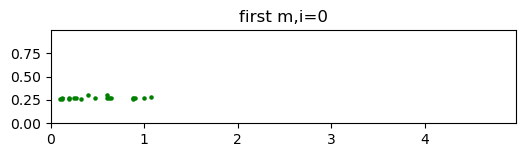

KeyboardInterrupt: 

findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

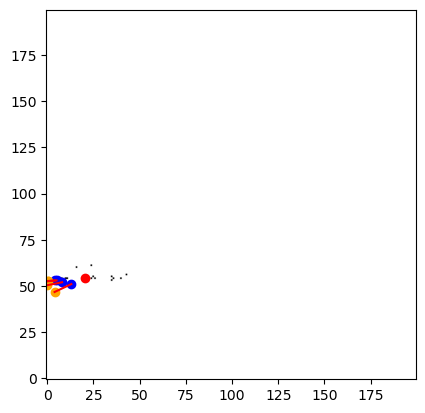

In [7]:
#code that runs the boundary exploration in the space given by the function myfN2
#set plotting:False in args dict when running for many iterations, so that no plots are shown
def rate_fn(*params):
    alpha_14, alpha_41, epsilon_1, epsilon_2 = params[0]
    epsilon_1 = np.log10(epsilon_1)
    epsilon_2 = np.log10(epsilon_2)
    right_cycles = [[2,3,4], [7,8,9], [2, 7, 8, 9, 4], [7, 2, 3, 4, 9], [7,2,3,8,9], [2,7,8,3,4], [2,3,8,9,7], [7,8,3,4,9]]
    wrong_cycles = [[2,1,0], [7,6,5], [2, 7, 6, 5, 0], [7, 2, 1, 0, 5], [7,2,1,6,5], [2,7,6,1,0], [2,1,6,5,7], [7,6,1,0,5]]
    return cycle_flux_fn(right_cycles, wrong_cycles, G, [(0,2), (5,7), (4,2), (9,7)], max_ss_rate_fn=get_best_steady_state, weight_mapping_fn=map_graph_weights_ten_states, alpha_32=alpha_32, \
                                              alpha_21=alpha_21, alpha_54=alpha_54, alpha_65=alpha_65,\
                                              alpha_21_w=alpha_21, alpha_32_w=alpha_32, alpha_54_w=alpha_54, alpha_65_w=alpha_65, dG_1=dG_1, dG_2=dG_2, dG_1_w = dG_1_w, dG_2_w = dG_2_w, \
                                              gamma=gamma, epsilon_1=epsilon_1, epsilon_2=epsilon_2, k_bT=k_bT, alpha_14=alpha_14, alpha_41=alpha_41)


outfolder="test"
if not os.path.isdir(outfolder):
    os.mkdir(outfolder)
name_save="namesave_g20000_sweep"
outfolder_final=outfolder
name='%s_last'%(name_save)


settings=defaultsettings.copy()
# constraints={1:{'target':0,'lt':1},3:{'target':2,'lt':1},5:{'target':4,'lt':1}} #the coefficients in the numerator are at most as large as the corresponding in the denominator

# settings['constraints']=constraints
settings['compute_x_y_f']=rate_fn
settings['npars']=4
# settings['mat'] = np.load(os.path.join(outfolder_final,'mat_namesave_g20000_sweep_6.npy'))
# settings['mat_pars'] = np.load(os.path.join(outfolder_final,'mat_pars_namesave_g20000_sweep_6.npy'))

#Initialise and get first 10 points

BE=BF.BoundaryExplorer(**settings)
BE.get_initial_points(10)

#Extend boundary

args=defaultargs.copy()
args["niters"]=20 #just for testing purposes
args['folder_save']=outfolder
args['name_save']=name_save
BE.extend_boundary(**args)


np.save(os.path.join(outfolder_final,'mat_'+name+'.npy'),BE.mat)
np.save(os.path.join(outfolder_final,'mat_pars_'+name+'.npy'),BE.mat_pars)

In [7]:
import matplotlib.pyplot as plt
import matplotlib.colors
import numpy as np
from matplotlib.colors import LinearSegmentedColormap, LogNorm, Normalize
from dynamic_catalysis_model import max_rate_six_states, cycle_flux_fn, osc_midpoint_six_states, map_graph_weights_six_states

import mpmath
import numpy as np
import bokeh.layouts
import bokeh.models
import bokeh.plotting

from IPython.display import display
from jupyter_bokeh.widgets import BokehModel
from bokeh.io import output_notebook, export_svg, export_png
from bokeh.plotting import figure
from ipywidgets import interact
import mpmath as mp
from bokeh.io import output_file, show, export_svgs
from bokeh.layouts import row
from bokeh.models import Ellipse, GraphRenderer, StaticLayoutProvider, Circle
from bokeh.palettes import Spectral6, Reds3, brewer
from bokeh.plotting import figure
from IPython.display import display
from bokeh.models import (Arrow, Label, NormalHead, OpenHead,
                          Plot, Range1d, TeeHead, VeeHead)
from bokeh.models import MathML
import pickle as pkl
import networkx as nx
output_notebook()


def heatmap(F1, F2, oscMidpoint, amplitude):
    turnover_fold_increase = np.zeros(F1.shape)
    selectivity = np.zeros(F1.shape)
    for i in range(F1.shape[0]):
        for j in range(F1.shape[1]):
            epsilon_1 = float(oscMidpoint + amplitude)
            epsilon_2 = float(oscMidpoint - amplitude)

            alpha_14 = F1[i, j]
            alpha_41 = F2[i, j] 

            right_cycles = [[2,3,4], [7,8,9], [2, 7, 8, 9, 4], [7, 2, 3, 4, 9], [7,2,3,8,9], [2,7,8,3,4], [2,3,8,9,7], [7,8,3,4,9]]
            wrong_cycles = [[2,1,0], [7,6,5], [2, 7, 6, 5, 0], [7, 2, 1, 0, 5], [7,2,1,6,5], [2,7,6,1,0], [2,1,6,5,7], [7,6,1,0,5]]
            J_turnover, J_futile = cycle_flux_fn(right_cycles, wrong_cycles, G, [(0,2), (5,7), (4,2), (9,7)], max_ss_rate_fn=get_best_steady_state, weight_mapping_fn=map_graph_weights_ten_states, alpha_32=alpha_32, \
                                                    alpha_21=alpha_21, alpha_54=alpha_54, alpha_65=alpha_65,\
                                                    alpha_21_w=alpha_21, alpha_32_w=alpha_32, alpha_54_w=alpha_54, alpha_65_w=alpha_65, dG_1=dG_1, dG_2=dG_2, dG_1_w = dG_1_w, dG_2_w = dG_2_w, \
                                                    gamma=gamma, epsilon_1=epsilon_1, epsilon_2=epsilon_2, k_bT=k_bT, alpha_14=alpha_14, alpha_41=alpha_41)
        
            turnover_fold_increase[i, j] = J_turnover
            selectivity[i, j] = J_futile 
    return turnover_fold_increase, selectivity

Loading BokehJS ...

findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family ['Lucida Sans'] not found. Falling back to DejaVu Sans.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida

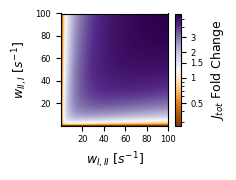

In [8]:
class MidPointLogNorm(LogNorm):
    def __init__(self, vmin=None, vmax=None, midpoint=None, clip=False):
        LogNorm.__init__(self,vmin=vmin, vmax=vmax, clip=clip)
        self.midpoint=midpoint
    def __call__(self, value, clip=None):
        # I'm ignoring masked values and all kinds of edge cases to make a
        # simple example...
        x, y = [np.log(self.vmin), np.log(self.midpoint), np.log(self.vmax)], [0, 0.5, 1]
        return np.ma.masked_array(np.interp(np.log(value), x, y))

max_frequency=100
n_points=100

frequencies_1 = np.linspace(1e-5, max_frequency, n_points)
frequencies_2 = np.linspace(1e-5, max_frequency, n_points)
amplitude = 2
oscMidpoint = epsilon_list[np.where(np.array(J_tot_list_cycle_r) == np.max(J_tot_list_cycle_r))[0][0]]


palette = brewer['PuOr'][11][::-1]
palette = bokeh.palettes.interp_palette(palette, 400)

F1, F2 = np.meshgrid(frequencies_1, frequencies_2)
turnover_fold_increase, selectivity = heatmap(F1, F2, oscMidpoint, amplitude)
bound = np.min([np.abs(np.max(np.log10(turnover_fold_increase))), np.abs(np.min(np.log10(turnover_fold_increase)))])

cmap = LinearSegmentedColormap.from_list('mycmap', palette)
plt.figure(figsize=(2.4, 1.9))
plt.imshow(turnover_fold_increase, extent=(1e-5, max_frequency, 1e-5, max_frequency), norm=MidPointLogNorm(vmin=np.min(turnover_fold_increase), vmax=np.max(turnover_fold_increase), midpoint=1), origin='lower', aspect='auto', cmap=cmap)
plt.xlabel(r'$w_{I,II}\ [s^{-1}]$', fontsize=9, fontdict={'fontname': 'Lucida Sans'})
plt.ylabel(r'$w_{II,I}\ [s^{-1}]$', fontsize=9, fontdict={'fontname': 'Lucida Sans'})
plt.xticks([20, 40, 60, 80, 100], fontsize=6)
plt.yticks([20, 40, 60, 80, 100], fontsize=6)
ax = plt.gca()
for tick in ax.get_xticklabels():
    tick.set_fontname("Lucida Sans")
for tick in ax.get_yticklabels():
    tick.set_fontname("Lucida Sans")
cbar = plt.colorbar(label='$J_{tot}$ Fold Change')
cbar.set_label('$J_{tot}$ Fold Change', fontdict={'fontname': 'Lucida Sans'}, fontsize=9)
cbar.set_ticks([0.5, 1, 1.5, 2, 3])
cbar.set_ticklabels([0.5, 1, 1.5, 2, 3], fontdict={'fontname': 'Lucida Sans'}, fontsize=6)
plt.tight_layout()

findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findf

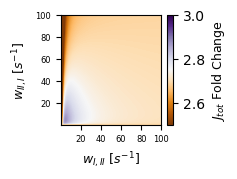

In [13]:
import matplotlib as mpl
cmap = LinearSegmentedColormap.from_list('mycmap', palette)
plt.figure(figsize=(2.4, 1.9))
plt.imshow(selectivity, extent=(1e-5, max_frequency, 1e-5, max_frequency), norm=mpl.colors.Normalize(vmin=2.5, vmax=3), origin='lower', aspect='auto', cmap=cmap)
plt.xlabel(r'$w_{I,II}\ [s^{-1}]$', fontsize=9, fontdict={'fontname': 'Lucida Sans'})
plt.ylabel(r'$w_{II,I}\ [s^{-1}]$', fontsize=9, fontdict={'fontname': 'Lucida Sans'})
plt.xticks([20, 40, 60, 80, 100], fontsize=6)
plt.yticks([20, 40, 60, 80, 100], fontsize=6)
ax = plt.gca()
for tick in ax.get_xticklabels():
    tick.set_fontname("Lucida Sans")
for tick in ax.get_yticklabels():
    tick.set_fontname("Lucida Sans")
cbar = plt.colorbar(label='$J_{tot}$ Fold Change')
cbar.set_label('$J_{tot}$ Fold Change', fontdict={'fontname': 'Lucida Sans'}, fontsize=9)
# cbar.set_ticks([0.5, 1, 1.5, 2, 3])
# cbar.set_ticklabels([0.5, 1, 1.5, 2, 3], fontdict={'fontname': 'Lucida Sans'}, fontsize=6)
plt.tight_layout()

In [10]:
selectivity

array([[2.22442372, 2.69029618, 2.69029961, ..., 2.69029615, 2.69029614,
        2.69029614],
       [1.90249532, 2.68779266, 2.80590712, ..., 2.70008218, 2.69995104,
        2.69982269],
       [1.90249229, 2.67855407, 2.82140827, ..., 2.70414828, 2.70397683,
        2.70380886],
       ...,
       [1.90247821, 2.21712165, 2.37160531, ..., 2.6883912 , 2.68841742,
        2.68844296],
       [1.90247817, 2.21492047, 2.36889854, ..., 2.68812681, 2.68815564,
        2.68818373],
       [1.90247813, 2.2127454 , 2.36621877, ..., 2.68786252, 2.68789395,
        2.68792459]])